# Assignment 18: Convolutional Neural Network (CNN) – CIFAR-10 Image Classification

In this assignment I build, train and evaluate a Convolutional Neural Network (CNN) to classify small colour images into 10 categories. I then experiment with different hyperparameters (number of convolutional layers, number of neurons, activation functions and optimizers) to see how they affect accuracy, loss and training speed.

Dataset:
- Name: CIFAR-10 (Canadian Institute For Advanced Research, 10 classes)
- Source: University of Toronto (Alex Krizhevsky, Vinod Nair and Geoffrey Hinton) – https://www.cs.toronto.edu/~kriz/cifar.html – loaded with keras.datasets.cifar10
- Content: 60,000 colour images of 32 x 32 pixels, already divided by the creators into 50,000 training and 10,000 test images
- Classes (target): airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck
- Features: the pixel values of each image (32 x 32 pixels x 3 colour channels: red, green and blue = 3,072 values per image)

A CNN is a type of neural network designed for images. Convolutional layers slide small filters over the image to detect patterns such as edges, colours and shapes. Pooling layers shrink the image while keeping the important information. Fully connected (dense) layers then combine these patterns to decide which class the image belongs to.

Steps I will follow:
1. Import libraries
2. Load the dataset and check its structure
3. Explore the data (class distribution and sample images)
4. Preprocess: normalize the pixels and create a validation set
5. Build and compile a baseline CNN
6. Train the CNN and monitor training and validation accuracy and loss
7. Evaluate it on the test data and plot the learning curves
8. Visualize the confusion matrix
9. Experiment with different layers, neurons, activation functions and optimizers
10. Discussion and conclusion

## Step 1: Import Libraries

In [1]:
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

keras.utils.set_random_seed(42)

print("Python version:", sys.version.split()[0])
print("TensorFlow version:", tf.__version__)
print("GPUs available:", tf.config.list_physical_devices("GPU"))

Python version: 3.14.2
TensorFlow version: 2.22.0-rc0
GPUs available: []


### Interpretation: Environment Check

I am using Python 3.14.2 and TensorFlow 2.22.0-rc0. "rc0" means it is a release candidate, a pre-release version, which pip installed because it supports my Python version. TensorFlow shows a warning that GPU support is not available on native Windows for TensorFlow 2.11 and newer, and the GPU list is empty. This means all models in this notebook will train on the CPU, so training will be slower than on a GPU. I will keep the models reasonably small and use a limited number of epochs, and I will record the training time of each model.

In [2]:
(X_train_full, y_train_full), (X_test, y_test) = keras.datasets.cifar10.load_data()

class_names = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

print("Training images:", X_train_full.shape, "| Training labels:", y_train_full.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 296s 2us/step
Training images: (50000, 32, 32, 3) | Training labels: (50000, 1)


C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\datasets\cifar.py:18: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  d = RestrictedUnpickler(f, encoding="bytes").load()


In [3]:
print("Test images:    ", X_test.shape, "| Test labels:    ", y_test.shape)

Test images:     (10000, 32, 32, 3) | Test labels:     (10000, 1)


In [5]:
print("Pixel data type:", X_train_full.dtype)


Pixel data type: uint8


In [6]:
print("Pixel value range:", X_train_full.min(), "to", X_train_full.max())

Pixel value range: 0 to 255


In [7]:
print("Label examples:", y_train_full[:5].ravel())

Label examples: [6 9 9 4 1]


In [8]:
print("Missing values (NaN) in images:", np.isnan(X_train_full).sum())

Missing values (NaN) in images: 0


### Interpretation: Dataset Structure

The CIFAR-10 dataset comes already split by its creators:
- Training set: 50,000 images with shape 32 x 32 x 3 (height x width x 3 colour channels: red, green and blue)
- Test set: 10,000 images with the same shape

Each image has one label, a number from 0 to 9 that stands for one of the 10 classes. For example, the first five training labels are 6, 9, 9, 4 and 1, which are frog, truck, truck, deer and automobile.

The pixel values are whole numbers (uint8) from 0 to 255, where 0 means no colour intensity and 255 means full intensity. Neural networks train better with small input values, so I will normalize the pixels to the range 0 to 1. There are no missing values.

Each image has 32 x 32 x 3 = 3,072 pixel values, so it is a much higher-dimensional input than the tabular datasets I used before. This is why a CNN, which is designed to find patterns in images, is a good choice.

## Step 3: Data Exploration – Class Distribution and Sample Images

            Train  Test
airplane     5000  1000
automobile   5000  1000
bird         5000  1000
cat          5000  1000
deer         5000  1000
dog          5000  1000
frog         5000  1000
horse        5000  1000
ship         5000  1000
truck        5000  1000


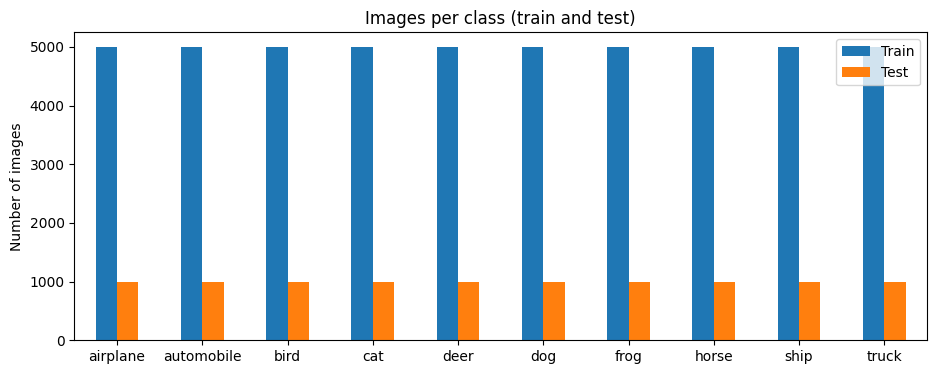

In [9]:
# 1. Class distribution (train and test)
train_counts = pd.Series(y_train_full.ravel()).value_counts().sort_index()
test_counts = pd.Series(y_test.ravel()).value_counts().sort_index()
dist = pd.DataFrame({"Train": train_counts.values, "Test": test_counts.values}, index=class_names)
print(dist)

dist.plot(kind="bar", figsize=(11, 4), rot=0)
plt.title("Images per class (train and test)"); plt.ylabel("Number of images"); plt.show()

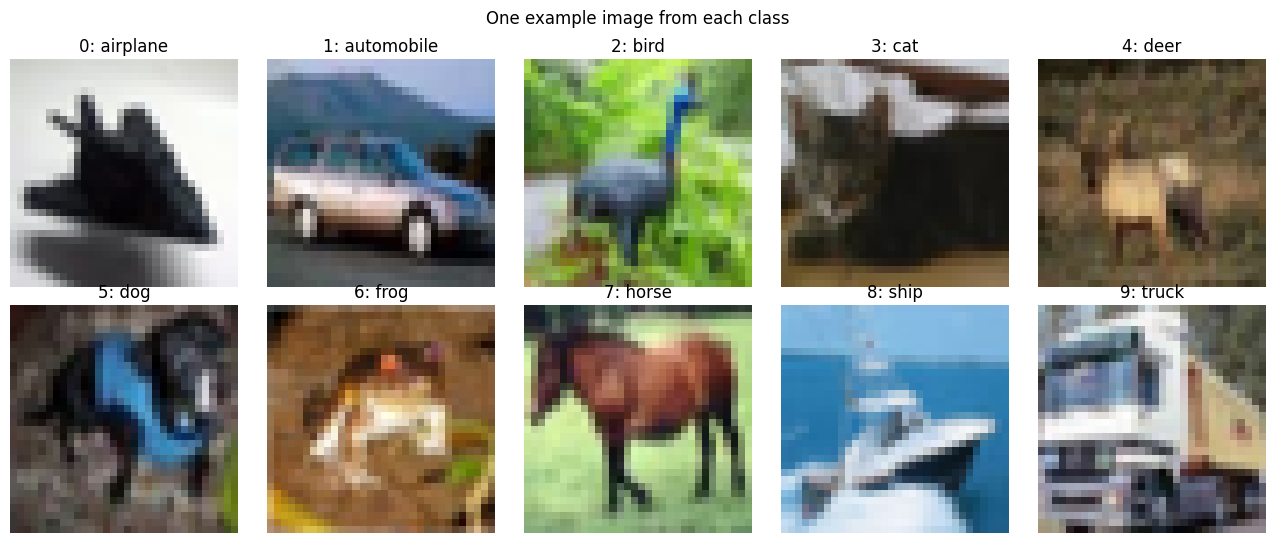

In [10]:
# 2. One sample image per class
fig, axes = plt.subplots(2, 5, figsize=(13, 5.5))
for i, ax in enumerate(axes.ravel()):
    idx = np.where(y_train_full.ravel() == i)[0][0]
    ax.imshow(X_train_full[idx])
    ax.set_title(f"{i}: {class_names[i]}"); ax.axis("off")
plt.suptitle("One example image from each class"); plt.tight_layout(); plt.show()

In [11]:
# 3. Average brightness per colour channel (training data)
print("Mean pixel value per channel (R, G, B):", X_train_full.mean(axis=(0, 1, 2)).round(1))

Mean pixel value per channel (R, G, B): [125.3 123.  113.9]


### Interpretation: Data Exploration

Class distribution:
The dataset is perfectly balanced: every class has exactly 5,000 training images and 1,000 test images. Because no class is over- or under-represented, accuracy is a fair metric, and no balancing techniques (like SMOTE) are needed.

Sample images:
The images are very small (32 x 32 pixels), so they look blurry and lose a lot of detail. Some are hard to recognize even for a person. For example, the airplane looks like a dark shape on a light background, and the dog is partly covered by something blue. Many images also have busy backgrounds, such as grass behind the bird, deer and horse, and water behind the ship. The model might partly learn from the background colour instead of the object itself.

Some classes look very similar at this resolution: cat and dog, deer and horse, and automobile and truck. I expect the model to confuse these pairs most often.

Pixel values:
The average pixel value per channel is 125.3 (red), 123.0 (green) and 113.9 (blue), out of 255. The images are slightly less blue on average, and the values sit in the middle of the 0 to 255 range.

## Step 4: Preprocessing – Normalize Pixel Values and Create a Validation Set

In [12]:
# 1. Normalize pixels from 0-255 to 0-1
X_train_full = X_train_full.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0


In [13]:
# 2. Validation set: 10% of the training images, stratified by class
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.1, random_state=42, stratify=y_train_full)

In [14]:
print("Train:", X_train.shape, "| Validation:", X_val.shape, "| Test:", X_test.shape)

Train: (45000, 32, 32, 3) | Validation: (5000, 32, 32, 3) | Test: (10000, 32, 32, 3)


In [15]:
print("Pixel range after normalizing:", X_train.min(), "to", X_train.max())

Pixel range after normalizing: 0.0 to 1.0


In [16]:
print("Images per class - validation:", np.bincount(y_val.ravel()))

Images per class - validation: [500 500 500 500 500 500 500 500 500 500]


### Interpretation: Preprocessing

I divided every pixel value by 255 to normalize it from the original 0 to 255 range to 0 to 1, and converted the values to float32. Small input values help the network train faster and more steadily, because the weight updates during training stay small and stable. Dividing by 255 is a fixed rule rather than something learned from the data, so applying it to the test set does not cause leakage.

I then set aside 10% of the training images as a validation set:
- Training: 45,000 images
- Validation: 5,000 images (exactly 500 per class, thanks to stratification)
- Test: 10,000 images

The validation set will be used to monitor accuracy and loss after each epoch and to compare experiments. The test set stays untouched until the final evaluation. The labels remain whole numbers from 0 to 9, because I will use sparse categorical crossentropy, which works directly with integer labels.

## Step 5: Build and Compile the Baseline CNN

In [17]:
def build_cnn(n_conv_blocks=2, dense_units=64, activation="relu", optimizer="adam", name="cnn"):
    model = keras.Sequential(name=name)
    model.add(keras.Input(shape=(32, 32, 3)))                       # input layer
    filters = 32
    for _ in range(n_conv_blocks):                                   # convolutional blocks
        model.add(layers.Conv2D(filters, (3, 3), activation=activation, padding="same"))
        model.add(layers.MaxPooling2D((2, 2)))
        filters *= 2                                                 # 32 -> 64 -> 128
    model.add(layers.Flatten())                                      # 3D feature maps -> 1D vector
    model.add(layers.Dense(dense_units, activation=activation))      # fully connected layer
    model.add(layers.Dense(10, activation="softmax"))                # output: 10 class probabilities
    model.compile(optimizer=optimizer, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

baseline = build_cnn(name="baseline_cnn")
baseline.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 32, 32, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 16, 16, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 16, 16, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 8, 8, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 4096)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │         262,208 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 282,250 (1.08 MB)

 Trainable params: 282,250 (1.08 MB)

 Non-trainable params: 0 (0.00 B)

### Interpretation: Baseline CNN Architecture

The baseline CNN has two convolutional blocks followed by fully connected layers:
- Input: 32 x 32 x 3 images
- Conv2D with 32 filters (output 32 x 32 x 32), then MaxPooling (16 x 16 x 32)
- Conv2D with 64 filters (output 16 x 16 x 64), then MaxPooling (8 x 8 x 64)
- Flatten: 8 x 8 x 64 = 4,096 values
- Dense layer with 64 neurons (ReLU)
- Output Dense layer with 10 neurons (softmax), one probability per class

Each MaxPooling layer halves the height and width (32 to 16 to 8), while the number of filters doubles (32 to 64), so the network trades spatial detail for more complex patterns.

The model has 282,250 trainable parameters. The two convolutional layers have only 19,392 parameters, because each 3 x 3 filter is shared across the whole image. The first dense layer has 262,208 parameters (93% of the total), because every one of the 4,096 inputs connects to every one of its 64 neurons. This shows why CNNs are efficient for images. It also suggests the dense layer is where overfitting is most likely.

The model is compiled with the Adam optimizer, sparse categorical crossentropy loss (suitable for integer class labels from 0 to 9), and accuracy as the metric.

## Step 6: Train the Baseline CNN

In [18]:
EPOCHS = 15
BATCH_SIZE = 64

start = time.time()
history_base = baseline.fit(X_train, y_train,
                            epochs=EPOCHS, batch_size=BATCH_SIZE,
                            validation_data=(X_val, y_val), verbose=1)
train_time_base = time.time() - start
print(f"\nTraining time: {train_time_base / 60:.1f} minutes ({train_time_base / EPOCHS:.1f} seconds per epoch)")

hist_df = pd.DataFrame(history_base.history).round(4)
hist_df.index = hist_df.index + 1
hist_df.index.name = "Epoch"
print(hist_df.to_string())

Epoch 1/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.4604 - loss: 1.5003 - val_accuracy: 0.5630 - val_loss: 1.2648
Epoch 2/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6058 - loss: 1.1238 - val_accuracy: 0.6414 - val_loss: 1.0605
Epoch 3/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.6550 - loss: 0.9886 - val_accuracy: 0.6688 - val_loss: 0.9757
Epoch 4/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.6840 - loss: 0.9060 - val_accuracy: 0.6800 - val_loss: 0.9370
Epoch 5/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7070 - loss: 0.8418 - val_accuracy: 0.6880 - val_loss: 0.9202
Epoch 6/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7279 - loss: 0.7875 - val_accuracy: 0.6890 - val_loss: 0.9183
Epoch 7/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.7452 - loss: 0.7372 - val_accuracy: 0.6894 - val_loss: 0.9216
Epoch 8/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.7620 - loss: 0.6913 - val_accu

### Interpretation: Training the Baseline CNN

I trained the baseline CNN for 15 epochs with a batch size of 64 (704 weight updates per epoch). Training took 2.1 minutes on the CPU, about 8.3 seconds per epoch.

Learning phase (epochs 1 to 6):
Training and validation results improved together. Validation accuracy rose from 56.3% to 68.9%, and validation loss fell from 1.265 to its lowest value of 0.918 at epoch 6.

Overfitting phase (epochs 7 to 15):
Training accuracy kept increasing, reaching 83.6% at epoch 15, and training loss kept falling to 0.473. However, validation accuracy stopped improving: it peaked at 69.6% at epoch 10 and then dropped to 67.6%. Validation loss rose from 0.918 back up to 1.100.

At the last epoch there is a 16-point gap between training accuracy (83.6%) and validation accuracy (67.6%). This is a clear sign of overfitting: after about 6 epochs, the model started memorizing the training images instead of learning patterns that work on new images. The best point to stop training would have been around epoch 6 (lowest validation loss). Techniques such as early stopping, dropout or data augmentation could reduce this overfitting.

## Step 7: Evaluate the Model on Test Data and Visualize Training vs Validation Loss and Accuracy

Test accuracy: 0.6814 | Test loss: 1.0921


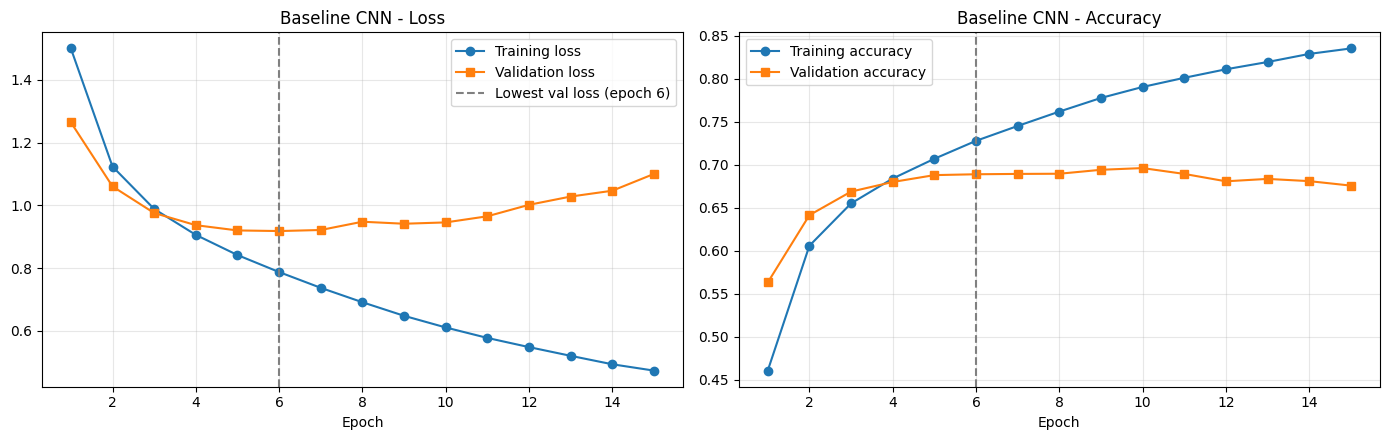

In [19]:
test_loss_base, test_acc_base = baseline.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc_base:.4f} | Test loss: {test_loss_base:.4f}")

def plot_history(history, title):
    h = history.history
    epochs = range(1, len(h["loss"]) + 1)
    best_ep = int(np.argmin(h["val_loss"])) + 1
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    axes[0].plot(epochs, h["loss"], "o-", label="Training loss")
    axes[0].plot(epochs, h["val_loss"], "s-", label="Validation loss")
    axes[0].axvline(best_ep, color="gray", linestyle="--", label=f"Lowest val loss (epoch {best_ep})")
    axes[0].set_title(f"{title} - Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(alpha=0.3)
    axes[1].plot(epochs, h["accuracy"], "o-", label="Training accuracy")
    axes[1].plot(epochs, h["val_accuracy"], "s-", label="Validation accuracy")
    axes[1].axvline(best_ep, color="gray", linestyle="--")
    axes[1].set_title(f"{title} - Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()

plot_history(history_base, "Baseline CNN")

In [20]:
# Store the results for the experiment comparison later
exp_results = [{"Model": "Baseline (2 conv, 64 dense, ReLU, Adam)",
                "Train acc (last)": history_base.history["accuracy"][-1],
                "Val acc (best)": max(history_base.history["val_accuracy"]),
                "Val loss (lowest)": min(history_base.history["val_loss"]),
                "Test acc": test_acc_base, "Test loss": test_loss_base,
                "Time (s)": round(train_time_base, 1), "Params": baseline.count_params()}]
histories = {"Baseline": history_base}

### Interpretation: Test Evaluation and Learning Curves

Test performance:
The baseline CNN reached 68.1% accuracy on the 10,000 test images, with a test loss of 1.092. Random guessing would give only 10% accuracy with 10 classes, so the model learned meaningful patterns. The test accuracy is very close to the final validation accuracy (67.6%), so the validation set was a reliable estimate of performance on new images.

Learning curves:
- In the first 3 epochs, training and validation loss both drop quickly. Validation is even slightly better than training at first, because training metrics are averaged while the model is still improving during each epoch.
- Validation loss reaches its lowest point at epoch 6 (0.918), shown by the grey dashed line.
- After epoch 6, the curves move apart: training loss keeps falling (from about 0.79 to 0.47), while validation loss rises again (to about 1.10). Training accuracy climbs to 83.6%, but validation accuracy stays flat at around 68 to 70%.

This is a clear case of overfitting, not underfitting: the model fits the training images better and better but does not improve on new images. Training for 15 epochs was too long for this model. Stopping around epoch 6, or adding regularization such as dropout, would likely give similar or better test accuracy with less overfitting.

## Step 8: Experimentation – Layers, Neurons, Activation Functions and Optimizers

In [21]:
experiments = [
    # (name in table, history key, build_cnn arguments)
    ("1 conv block",               "1 conv block",  dict(n_conv_blocks=1)),
    ("3 conv blocks",              "3 conv blocks", dict(n_conv_blocks=3)),
    ("256 dense neurons",          "256 neurons",   dict(dense_units=256)),
    ("tanh activation",            "tanh",          dict(activation="tanh")),
    ("SGD optimizer",              "SGD",           dict(optimizer="sgd")),
    ("RMSprop optimizer",          "RMSprop",       dict(optimizer="rmsprop")),
]

for label, key, kwargs in experiments:
    keras.utils.set_random_seed(42)
    model = build_cnn(name=key.replace(" ", "_"), **kwargs)
    start = time.time()
    hist = model.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
                     validation_data=(X_val, y_val), verbose=0)
    t = time.time() - start
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
    histories[key] = hist
    exp_results.append({"Model": label,
                        "Train acc (last)": hist.history["accuracy"][-1],
                        "Val acc (best)": max(hist.history["val_accuracy"]),
                        "Val loss (lowest)": min(hist.history["val_loss"]),
                        "Test acc": test_acc, "Test loss": test_loss,
                        "Time (s)": round(t, 1), "Params": model.count_params()})
    print(f"{label:<20} done in {t / 60:.1f} min | test acc {test_acc:.4f} | params {model.count_params():,}")

results_df = pd.DataFrame(exp_results).round(4)
results_df["Overfit gap"] = (results_df["Train acc (last)"] - results_df["Val acc (best)"]).round(4)
print("\n" + results_df.to_string(index=False))

1 conv block         done in 1.3 min | test acc 0.6098 | params 525,898
3 conv blocks        done in 2.2 min | test acc 0.7022 | params 225,034
256 dense neurons    done in 1.8 min | test acc 0.6602 | params 1,070,794
tanh activation      done in 2.0 min | test acc 0.6293 | params 282,250
SGD optimizer        done in 1.9 min | test acc 0.6075 | params 282,250
RMSprop optimizer    done in 1.9 min | test acc 0.6609 | params 282,250

                                  Model  Train acc (last)  Val acc (best)  Val loss (lowest)  Test acc  Test loss  Time (s)  Params  Overfit gap
Baseline (2 conv, 64 dense, ReLU, Adam)            0.8355          0.6962             0.9183    0.6814     1.0921     124.6  282250       0.1393
                           1 conv block            0.7814          0.6350             1.0553    0.6098     1.2787      76.9  525898       0.1464
                          3 conv blocks            0.8900          0.7144             0.8428    0.7022     1.3201     129.6  22503

### Interpretation: Hyperparameter Experiments

I trained 6 variations of the baseline CNN, changing one setting at a time, with the same data, 15 epochs and batch size 64.

Number of convolutional layers:
- 3 convolutional blocks gave the best test accuracy (70.2%, up from 68.1%) and the best validation loss (0.843), even though this model has the fewest parameters (225,034). The extra pooling step shrinks the image to 4 x 4 before the dense layer, so the dense layer needs fewer weights, and the third block (128 filters) can learn more complex shapes.
- 1 convolutional block performed much worse (61.0%). It cannot learn complex patterns, and because the image is only shrunk once, its dense layer receives 8,192 inputs, giving it 525,898 parameters. It was the fastest model (77 seconds).
So yes, accuracy improved with more convolutional layers.

Number of neurons in the fully connected layer:
Increasing the dense layer from 64 to 256 neurons quadrupled the parameters (1,070,794) but lowered test accuracy to 66.0%. Training accuracy reached 94.9%, giving the largest overfitting gap together with tanh (about 0.26), and the test loss rose to 1.946. A bigger dense layer mainly helped the model memorize the training images.

Activation function:
Using tanh instead of ReLU lowered test accuracy to 62.9%, and it had the largest overfitting gap (0.264). ReLU worked better for the hidden layers, which matches why it is the standard choice: it trains efficiently and avoids the vanishing gradient problem that tanh can have.

Optimizers:
- Adam (baseline) gave the best result of the three optimizers (68.1%).
- RMSprop reached a similar best validation accuracy (69.3%) but then overfitted more (gap 0.230), ending at 66.1% test accuracy with a higher test loss (1.667).
- SGD with its default learning rate learned much more slowly: training accuracy was only 66.9% after 15 epochs and test accuracy 60.8%. It had the smallest overfitting gap (0.060), but this is underfitting: the model had not finished learning.
The training time per model was similar for all optimizers (113 to 125 seconds), because each epoch does the same amount of work. The real difference in speed is how quickly each optimizer improves accuracy per epoch. Adam and RMSprop learn quickly, while SGD needs many more epochs.

Overfitting and underfitting:
Most models overfitted (training accuracy 78% to 95%, best validation accuracy 63% to 71%). The models with more capacity or less suitable settings (256 neurons, tanh, RMSprop) overfitted the most. Only SGD showed underfitting. The overfitted models also had much higher test loss, which means they made confident wrong predictions.

## Step 9: Visual Comparison of the Experiments

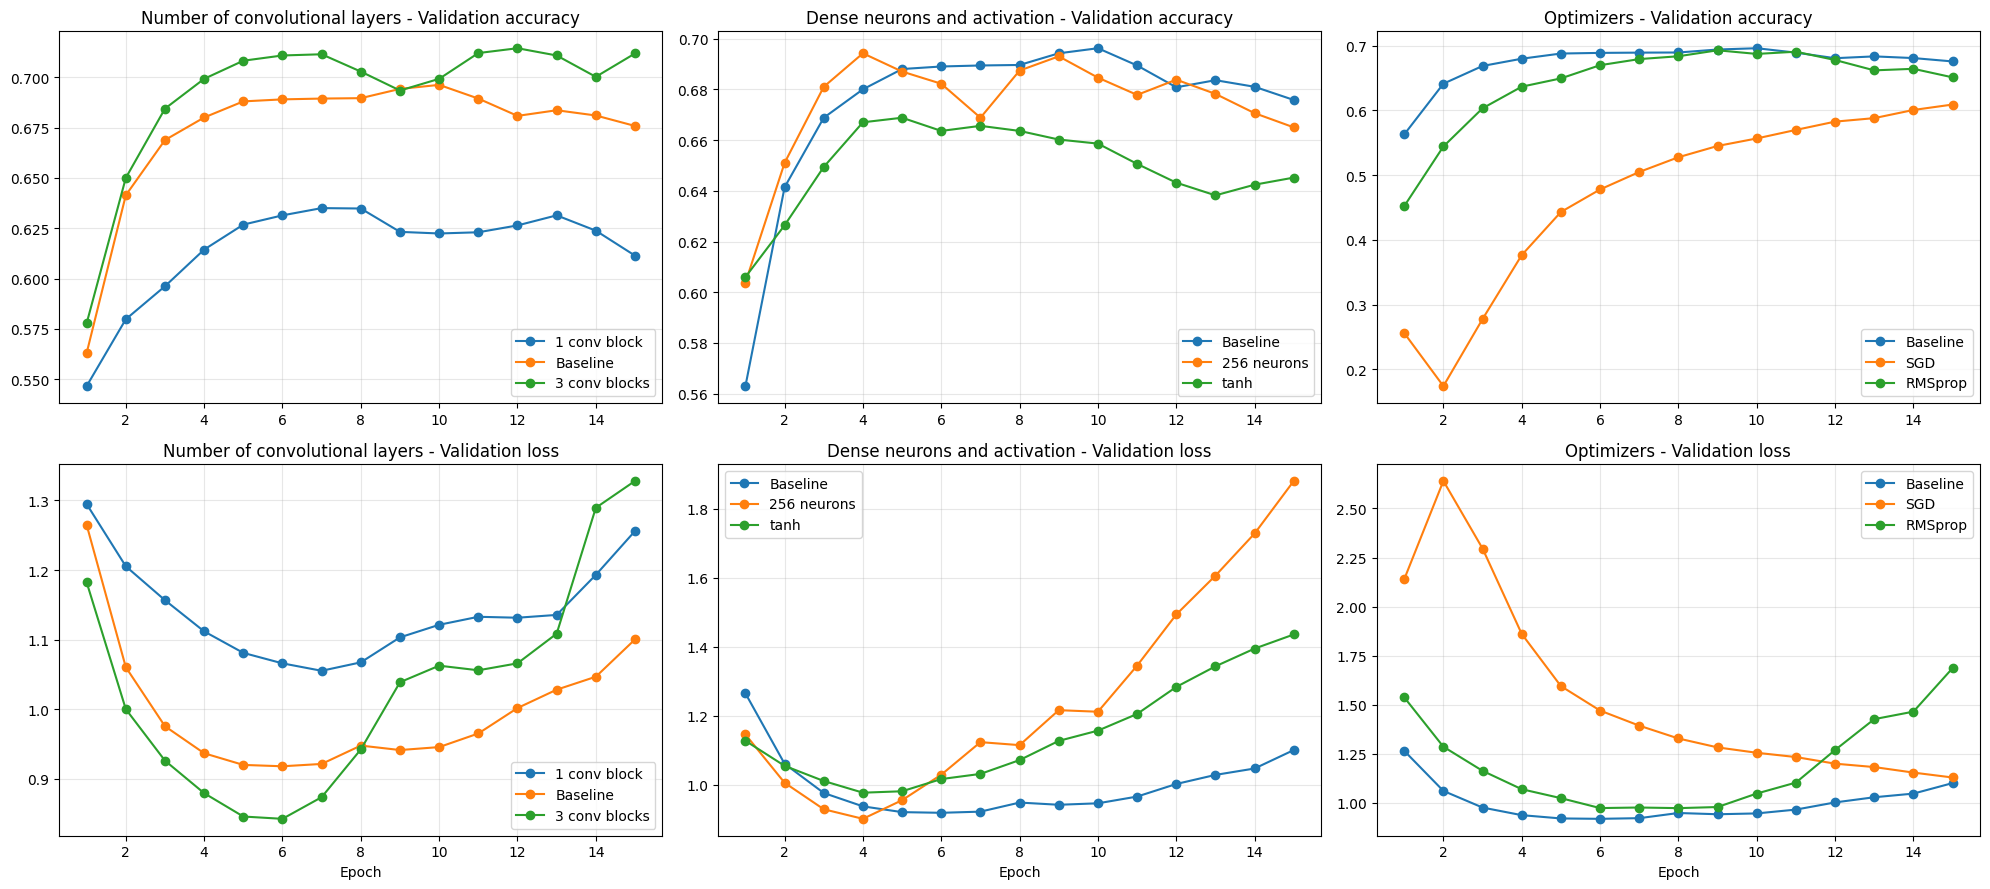

In [22]:
groups = {"Number of convolutional layers": ["1 conv block", "Baseline", "3 conv blocks"],
          "Dense neurons and activation": ["Baseline", "256 neurons", "tanh"],
          "Optimizers": ["Baseline", "SGD", "RMSprop"]}

fig, axes = plt.subplots(2, 3, figsize=(20, 9))
for col, (title, keys) in enumerate(groups.items()):
    for k in keys:
        h = histories[k].history
        ep = range(1, len(h["val_loss"]) + 1)
        axes[0, col].plot(ep, h["val_accuracy"], marker="o", label=k)
        axes[1, col].plot(ep, h["val_loss"], marker="o", label=k)
    axes[0, col].set_title(f"{title} - Validation accuracy"); axes[0, col].legend(); axes[0, col].grid(alpha=0.3)
    axes[1, col].set_title(f"{title} - Validation loss"); axes[1, col].legend(); axes[1, col].grid(alpha=0.3)
    axes[1, col].set_xlabel("Epoch")
plt.tight_layout(); plt.show()

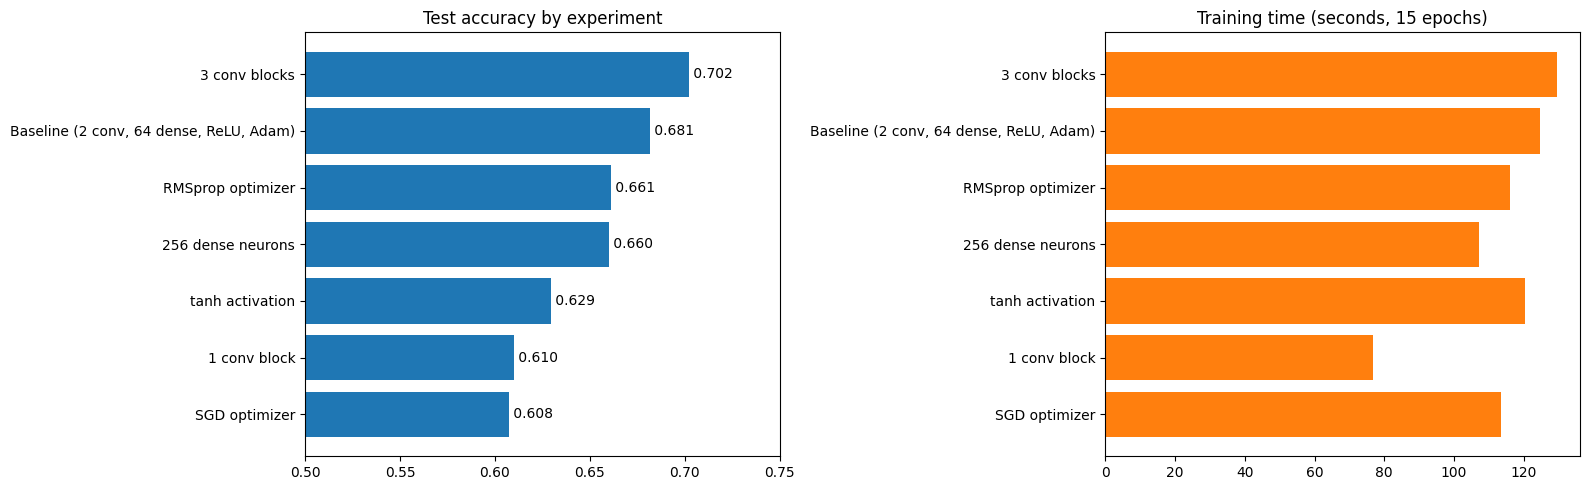

In [23]:
# Test accuracy and training time
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
order = results_df.sort_values("Test acc")
axes[0].barh(order["Model"], order["Test acc"], color="tab:blue")
for i, v in enumerate(order["Test acc"]):
    axes[0].text(v, i, f" {v:.3f}", va="center")
axes[0].set_xlim(0.5, 0.75); axes[0].set_title("Test accuracy by experiment")
axes[1].barh(order["Model"], order["Time (s)"], color="tab:orange")
axes[1].set_title("Training time (seconds, 15 epochs)")
plt.tight_layout(); plt.show()

### Interpretation: Visual Comparison of the Experiments

Number of convolutional layers:
The model with 3 convolutional blocks had the highest validation accuracy for almost every epoch (around 71%) and reached the lowest validation loss of all models (about 0.84 at epoch 6). After that, its validation loss rose sharply to about 1.33 by epoch 15, so it learns the most but also needs to be stopped early. The 1-block model stayed around 62 to 63% validation accuracy and never got its validation loss below about 1.05, which shows it is too simple for this task.

Dense neurons and activation:
The 256-neuron model reached its lowest validation loss early (epoch 4) and then its loss rose steeply to about 1.88, the strongest overfitting of all experiments. The tanh model's validation accuracy peaked at about 67% around epoch 5 and then slowly declined, while its validation loss kept rising.

Optimizers:
Adam learned fastest, reaching about 68% validation accuracy by epoch 4. RMSprop got there by about epoch 7, then overfitted after epoch 9 (its validation loss rose to about 1.7). SGD learned much more slowly: its validation accuracy rose steadily from about 25% to 61%, and its validation loss was still falling at epoch 15. This means SGD was underfitting and would need many more epochs or a higher learning rate. The training time per model was similar for all optimizers (about 113 to 125 seconds for 15 epochs), so the real difference in speed is how many epochs each optimizer needs to learn, not how long each epoch takes.

Summary:
3 convolutional blocks gave the best test accuracy (70.2%), followed by the baseline (68.1%). Every model except SGD showed overfitting after about 4 to 8 epochs, which shows that the number of epochs should be controlled with early stopping and that the models would benefit from regularization.

## Step 10: Final Improved Model and Confusion Matrix

Epoch 1/40
704/704 - 12s - 17ms/step - accuracy: 0.3291 - loss: 1.8062 - val_accuracy: 0.4816 - val_loss: 1.4455
Epoch 2/40
704/704 - 10s - 15ms/step - accuracy: 0.4608 - loss: 1.4861 - val_accuracy: 0.5634 - val_loss: 1.2471
Epoch 3/40
704/704 - 10s - 15ms/step - accuracy: 0.5106 - loss: 1.3579 - val_accuracy: 0.6132 - val_loss: 1.0932
Epoch 4/40
704/704 - 10s - 15ms/step - accuracy: 0.5479 - loss: 1.2680 - val_accuracy: 0.6148 - val_loss: 1.0699
Epoch 5/40
704/704 - 10s - 15ms/step - accuracy: 0.5733 - loss: 1.2048 - val_accuracy: 0.6496 - val_loss: 0.9899
Epoch 6/40
704/704 - 10s - 15ms/step - accuracy: 0.5908 - loss: 1.1523 - val_accuracy: 0.6750 - val_loss: 0.9333
Epoch 7/40
704/704 - 10s - 15ms/step - accuracy: 0.6072 - loss: 1.1128 - val_accuracy: 0.6844 - val_loss: 0.9051
Epoch 8/40
704/704 - 10s - 15ms/step - accuracy: 0.6144 - loss: 1.0833 - val_accuracy: 0.6760 - val_loss: 0.9304
Epoch 9/40
704/704 - 10s - 14ms/step - accuracy: 0.6284 - loss: 1.0506 - val_accuracy: 0.7038 - 

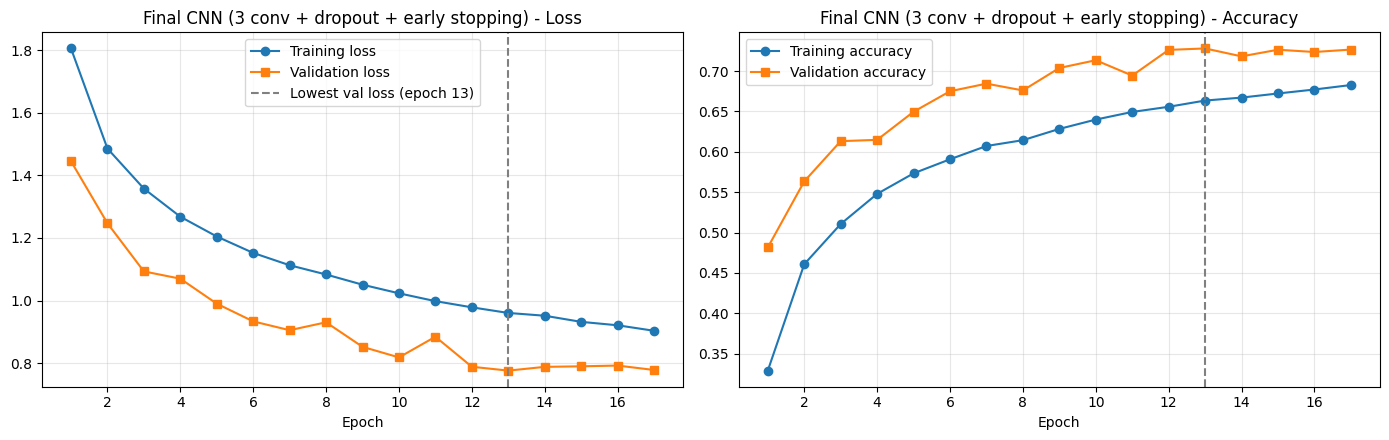

In [24]:
keras.utils.set_random_seed(42)

final_model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"), layers.MaxPooling2D((2, 2)), layers.Dropout(0.25),
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"), layers.MaxPooling2D((2, 2)), layers.Dropout(0.25),
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"), layers.MaxPooling2D((2, 2)), layers.Dropout(0.25),
    layers.Flatten(),
    layers.Dense(64, activation="relu"), layers.Dropout(0.5),
    layers.Dense(10, activation="softmax")
], name="final_cnn")
final_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)

start = time.time()
history_final = final_model.fit(X_train, y_train, epochs=40, batch_size=BATCH_SIZE,
                                validation_data=(X_val, y_val), callbacks=[early_stop], verbose=2)
t_final = time.time() - start

test_loss_f, test_acc_f = final_model.evaluate(X_test, y_test, verbose=0)
best_ep = int(np.argmin(history_final.history["val_loss"])) + 1
print(f"\nStopped after {len(history_final.history['loss'])} epochs (best epoch {best_ep}) in {t_final / 60:.1f} min")
print(f"Final model test accuracy: {test_acc_f:.4f} | test loss: {test_loss_f:.4f}")
plot_history(history_final, "Final CNN (3 conv + dropout + early stopping)")

### Interpretation: Final Improved Model

Based on my experiments, I built a final model with 3 convolutional blocks (the best architecture), added dropout (25% after each pooling layer and 50% before the output layer) to reduce overfitting, and used early stopping, which watches validation loss and restores the best weights.

Training:
Training stopped automatically after 17 epochs. The best epoch was 13, with a validation loss of 0.776, and the model was restored to that point. Training took 2.9 minutes.

Learning curves:
Unlike the baseline, the validation loss kept decreasing and then levelled off. It did not rise again, so there is no sign of overfitting. Validation accuracy was even higher than training accuracy throughout training (about 72.7% compared with 66 to 68%). This happens because dropout is only active during training, so the training accuracy is measured while some neurons are switched off, while validation uses the full network.

Test results:
The final model reached 72.5% test accuracy with a test loss of 0.802. That is the best of all models: 4.3 points better than the baseline (68.1%) and 2.3 points better than the 3-block model without dropout (70.2%). The much lower test loss (0.802 compared with 1.092 for the baseline) shows the model makes fewer overconfident mistakes. Dropout and early stopping solved the overfitting problem I saw in the earlier models.

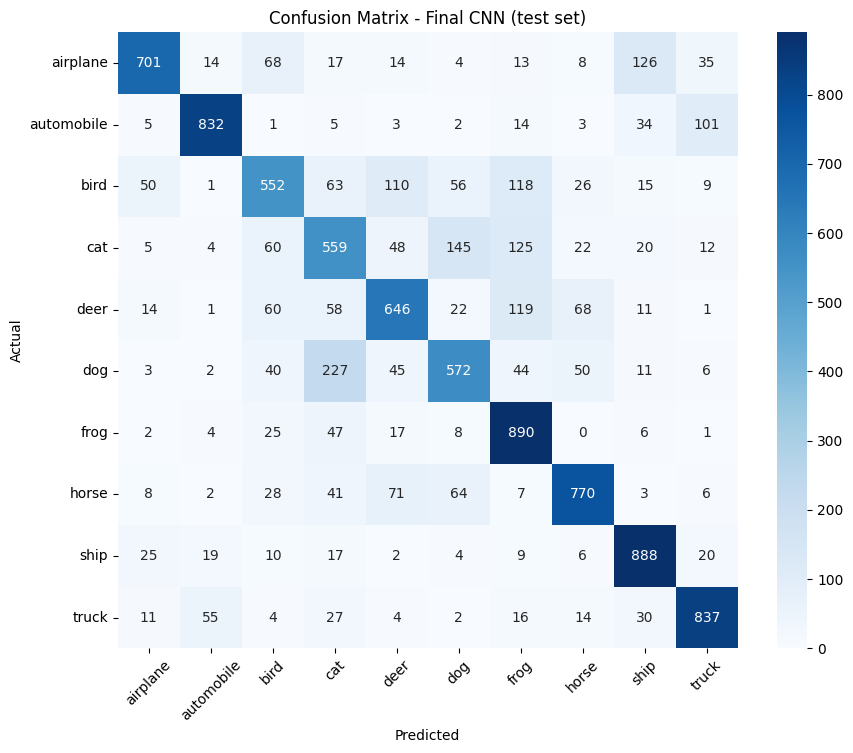

              precision    recall  f1-score   support

    airplane      0.851     0.701     0.769      1000
  automobile      0.891     0.832     0.860      1000
        bird      0.651     0.552     0.597      1000
         cat      0.527     0.559     0.542      1000
        deer      0.673     0.646     0.659      1000
         dog      0.651     0.572     0.609      1000
        frog      0.657     0.890     0.756      1000
       horse      0.796     0.770     0.783      1000
        ship      0.776     0.888     0.828      1000
       truck      0.814     0.837     0.825      1000

    accuracy                          0.725     10000
   macro avg      0.729     0.725     0.723     10000
weighted avg      0.729     0.725     0.723     10000



In [25]:
# Confusion matrix on the test set
y_pred = final_model.predict(X_test, verbose=0).argmax(axis=1)
cm = confusion_matrix(y_test.ravel(), y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix - Final CNN (test set)")
plt.xticks(rotation=45); plt.show()

print(classification_report(y_test.ravel(), y_pred, target_names=class_names, digits=3))



### Interpretation: Confusion Matrix and Per-Class Performance

Overall, the final model correctly classified 72.5% of the 10,000 test images (macro-average precision 0.729, recall 0.725 and F1-score 0.723).

Classes the model handles best:
- Frog (recall 0.890), ship (0.888), truck (0.837) and automobile (0.832, with the best F1-score of 0.860).
Vehicles generally performed better than animals, because they have clearer, more consistent shapes.

Classes the model struggles with:
- Cat (recall 0.559, the lowest F1-score at 0.542), bird (recall 0.552) and dog (recall 0.572).
Animals vary much more in pose, colour and background, and at only 32 x 32 pixels many details are lost.

Most common mistakes (actual to predicted):
- Dog predicted as cat: 227 images, and cat predicted as dog: 145. This is the biggest confusion, because cats and dogs look very similar at this resolution (similar size, fur and body shape).
- Airplane predicted as ship: 126. Both usually appear on a blue background (sky or water), so the model partly relies on the background colour.
- Cat, deer and bird predicted as frog: 125, 119 and 118. Frog has high recall (0.890) but low precision (0.657), which means the model uses "frog" as a catch-all for blurry animals with brown or green textures.
- Automobile predicted as truck: 101, because the two vehicle types have similar shapes.

These results confirm what I expected from exploring the sample images: the model mixes up classes that look similar or appear on similar backgrounds, especially cat and dog.

## Step 11: Discussion and Conclusion

### Summary of all models

| Model | Params | Train acc (last) | Best val acc | Test acc | Test loss | Time | Overfitting |
|---|---|---|---|---|---|---|---|
| Baseline (2 conv, 64 dense, ReLU, Adam) | 282,250 | 0.836 | 0.696 | 0.681 | 1.092 | 125 s | Yes (after epoch 6) |
| 1 conv block | 525,898 | 0.781 | 0.635 | 0.610 | 1.279 | 77 s | Yes |
| 3 conv blocks | 225,034 | 0.890 | 0.714 | 0.702 | 1.320 | 130 s | Yes (strong) |
| 256 dense neurons | 1,070,794 | 0.949 | 0.694 | 0.660 | 1.946 | 107 s | Yes (strongest) |
| tanh activation | 282,250 | 0.933 | 0.669 | 0.629 | 1.512 | 120 s | Yes (strong) |
| SGD optimizer | 282,250 | 0.669 | 0.609 | 0.608 | 1.127 | 113 s | No (underfitting) |
| RMSprop optimizer | 282,250 | 0.923 | 0.693 | 0.661 | 1.667 | 116 s | Yes |
| **Final: 3 conv + dropout + early stopping** | – | 0.683* | 0.728 | **0.725** | **0.802** | 174 s | **No** |

*Training accuracy is measured with dropout active, so it is lower than validation accuracy.

### Discussion of model performance
**Overfitting was the main challenge.** The baseline CNN's validation loss reached its lowest point at epoch 6 and then rose, while training accuracy kept climbing to 83.6% and validation accuracy stayed around 68 to 70%. Most experiment models showed the same pattern, and the models with more capacity overfitted the most (the 256-neuron model reached 94.9% training accuracy but only 66.0% test accuracy). Adding dropout and early stopping solved this: the final model's validation loss kept decreasing and levelled off instead of rising, and its test loss dropped to 0.802.

**Did accuracy improve with more layers or different activation functions?**
- More convolutional layers helped: 3 blocks reached 70.2% compared with 68.1% for 2 blocks and 61.0% for 1 block. Interestingly, the deeper model had fewer parameters, because the extra pooling layer shrinks the image before the dense layer.
- More neurons in the dense layer did not help: it mostly increased memorization.
- ReLU worked better than tanh (68.1% compared with 62.9%), and tanh also overfitted more.

**How did the optimizer affect training speed and performance?**
All optimizers took a similar time per epoch (about 113 to 125 seconds for 15 epochs), so the difference is in how quickly they learn. Adam learned fastest (about 68% validation accuracy by epoch 4) and gave the best result. RMSprop reached a similar peak by about epoch 7 but then overfitted more. SGD with its default learning rate learned very slowly and was still improving at epoch 15 (60.8% test accuracy), so it underfitted and would need more epochs, a higher learning rate, or momentum.

**Signs of overfitting or underfitting:** overfitting appeared in every model except SGD, usually after 4 to 8 epochs. SGD was the only case of underfitting.

**Per-class insights:** the final model classified vehicles and frogs best (recall about 83 to 89%) and struggled with cats, birds and dogs (recall about 55 to 57%). The biggest confusion was dog predicted as cat (227 images), followed by cat predicted as dog (145) and airplane predicted as ship (126), which are visually similar classes or classes with similar backgrounds.

### Conclusion
The CNN learned to classify the 10 CIFAR-10 classes far better than random guessing (10%). The baseline reached 68.1% test accuracy, and the final model reached **72.5%**. The most important findings from the experiments:
1. **Deeper convolutional layers improved accuracy** more than adding neurons to the dense layer.
2. **ReLU and Adam were the best choices** for activation function and optimizer.
3. **Overfitting was the main limitation**, and **dropout plus early stopping** gave the biggest improvement in both accuracy and test loss.

Further improvements could include data augmentation (random flips, shifts and rotations to create more varied training images), batch normalization, more convolutional filters, or transfer learning from a model pre-trained on a large image dataset. Training on a GPU would make these larger experiments faster.